In [2]:
import json, collections, pandas as pd

g = json.load(open("../data/ptal2023.geojson", encoding="utf-8"))
feats = g["features"]
print("features:", len(feats))
print("geometry types:", collections.Counter(
    f["geometry"]["type"] if f["geometry"] else "missing" for f in feats))

props = pd.DataFrame([f["properties"] for f in feats])
print("unique GridIDs:", props["GridID"].is_unique)
print("nulls:\n", props.isna().sum())
print(props[["BUS", "LUL", "RAIL", "TRAM", "AI"]].describe())

features: 159451
geometry types: Counter({'Polygon': 159447, 'MultiPolygon': 4})
unique GridIDs: True
nulls:
 FID              0
GridID           0
BUS              0
LUL              0
RAIL             0
TRAM             0
AI               0
PTAL_2023        0
Shape_Leng       0
Shape__Area      0
Shape__Length    0
dtype: int64
                 BUS            LUL           RAIL           TRAM  \
count  159451.000000  159451.000000  159451.000000  159451.000000   
mean        5.506190       1.630617       1.224719       0.064483   
std         5.391125       4.524270       3.342738       0.490551   
min         0.000000       0.000000       0.000000       0.000000   
25%         1.807292       0.000000       0.000000       0.000000   
50%         4.331503       0.000000       0.000000       0.000000   
75%         7.770573       0.000000       1.449292       0.000000   
max        55.171935      64.999578      62.157080       9.846775   

                  AI  
count  159451.000000  


In [3]:
import json, pandas as pd
rows = json.load(open("../data/ptal_compact.json"))
df = pd.DataFrame(rows, columns=["lon", "lat", "level", "ai", "bus"])
labels = ["0","1a","1b","2","3","4","5","6a","6b"]
df["label"] = df["level"].map(dict(enumerate(labels)))
df.head()

,lon,lat,level,ai,bus,label
0,-0.12120,51.31100,3,5.10,5.10,2
1,-0.11976,51.31098,2,3.61,3.61,1b
2,-0.11833,51.31095,2,3.20,3.20,1b
3,-0.11690,51.31093,1,2.29,2.29,1a
4,-0.11546,51.31091,2,4.66,4.66,1b


In [4]:
raw = sum(1 for l in open("../data/ptal2023.geojson", encoding="utf-8")
          if l.lstrip().startswith('{ "type": "Feature"'))
print("raw features:", raw, "| rows kept:", len(df))
print("nulls:", df.isna().sum().sum(), "| duplicate squares:", df.duplicated(["lon","lat"]).sum())
print(df[["lon","lat","ai","bus"]].describe().loc[["min","max"]])

raw features: 159451 | rows kept: 159451
nulls: 0 | duplicate squares: 0
         lon       lat      ai    bus
min -0.50974  51.28733    0.00   0.00
max  0.33344  51.69157  155.53  55.17


label
0     18.8
1a     9.6
1b    18.6
2     25.1
3     12.4
4      6.2
5      3.4
6a     3.8
6b     2.0
Name: proportion, dtype: float64


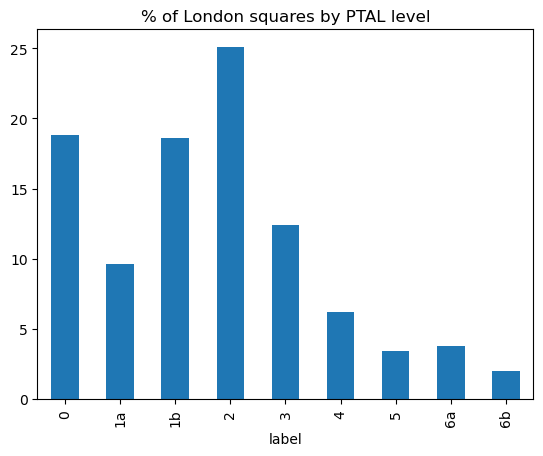

In [5]:
dist = df["label"].value_counts(normalize=True).reindex(labels).mul(100).round(1)
print(dist)
dist.plot(kind="bar", title="% of London squares by PTAL level");

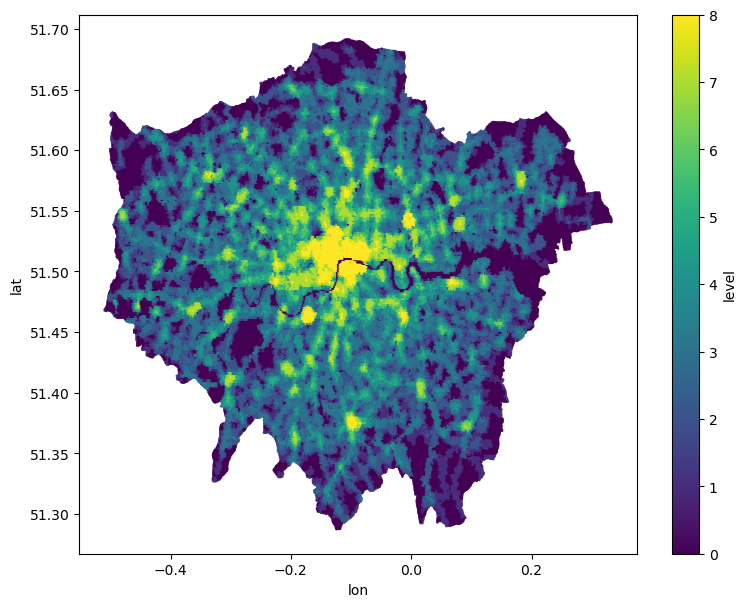

In [6]:
df.plot.scatter("lon", "lat", c="level", cmap="viridis", s=0.3, figsize=(9,7));

In [8]:
df["bus_only"] = (df["bus"] > 0) & ((df["ai"] - df["bus"]).abs() < 0.01)
print("% squares served by bus alone:", round(df["bus_only"].mean()*100, 1))

% squares served by bus alone: 41.8


In [9]:
gap = (props[["BUS","LUL","RAIL","TRAM"]].sum(axis=1) - props["AI"]).abs().max()
print("max gap between sum of modes and AI:", gap)

max gap between sum of modes and AI: 1.8700006876315456e-08
